# 🏋️ نظام تحليل مخاطر انسحاب المشتركين من النادي الرياضي

### Gym Member Churn Prediction & Retention Analysis

**مشروع تطبيقي في تعلم الآلة — دفتر مشروح باللغة العربية**

يستخدم هذا المشروع بيانات مشتركين منشورة لفهم الأنماط المرتبطة بالانسحاب، ومقارنة عدة خوارزميات تصنيف، واختبار أثر هندسة الخصائص، ثم تقييم الإعداد الأفضل على مجموعة اختبار منفصلة.

> **مهم:** الأرقام والرسوم في هذا الدفتر ناتجة عن التجارب المنفذة على ملف البيانات المرفق. النموذج يساعد على تحليل مخاطر الانسحاب، لكنه لا يثبت وحده أن أداءً مشابهًا سيتحقق في نادٍ حقيقي.

## فهرس الدفتر

1. [المشكلة والقيمة العملية](#المشكلة)
2. [تحميل البيانات وتدقيقها](#تحميل-البيانات)
3. [قاموس الأعمدة](#قاموس-الأعمدة)
4. [التحليل الاستكشافي والرسوم](#التحليل-الاستكشافي)
5. [هندسة الخصائص](#هندسة-الخصائص)
6. [منهجية التجارب ومقارنة النماذج](#منهجية-التجارب)
7. [اختيار النموذج والعتبة](#اختيار-النموذج)
8. [التقييم النهائي وتحليل الأخطاء](#التقييم-النهائي)
9. [تفسير النموذج وحدود المشروع](#حدود-المشروع)
10. [تجربة تنبؤ ومصطلحات ومراجع](#تجربة-تنبؤ)

<a id="المشكلة"></a>
## 1. المشكلة والقيمة العملية

قد يجد مدير النادي صعوبة في تحديد المشتركين الذين تظهر في سجلاتهم أنماط مرتبطة بالانسحاب. الهدف من هذا المشروع هو تدريب نموذج يتعلم من خصائص العضوية وسلوك الحضور ليتنبأ بملصق `Churn` المسجل في البيانات.

**المستفيدون المحتملون:** مدير النادي، وموظفو الاشتراكات، وفريق خدمة العملاء.

**أسئلة المشروع:**
- هل يمكن للنموذج تعلم الأنماط المرتبطة بالانسحاب أفضل من نموذج مرجعي بسيط؟
- أي الخوارزميات تحقق أفضل أداء في التحقق المتقاطع؟
- هل تضيف الخصائص المشتقة تحسنًا يتجاوز الخصائص الأصلية؟
- ما نوع الأخطاء التي يقع فيها النموذج، وما أثر عتبة القرار؟

**ما لا يدعيه المشروع:** لا يثبت النموذج أن سبب الانسحاب هو خاصية معينة، ولا يثبت الأداء على الأشهر القادمة أو على نادٍ آخر دون بيانات زمنية واختبار خارجي.

<a id="تحميل-البيانات"></a>
## 2. تحميل البيانات وتدقيقها

سنبدأ بفحص الملف نفسه، لا بالاكتفاء بوصف صفحة التنزيل. نتحقق من الحجم، وأسماء الأعمدة، والأنواع، والقيم المفقودة، والتكرار، وتوزيع الهدف.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# يعمل الدفتر عند تشغيله من مجلد المشروع أو من مجلد notebooks داخله.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "gym_churn_us.csv").exists() and (PROJECT_ROOT.parent / "data" / "gym_churn_us.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "gym_churn_us.csv"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODEL_PATH = PROJECT_ROOT / "models" / "gym_churn_model.joblib"

if not DATA_PATH.exists():
    raise FileNotFoundError("لم أجد data/gym_churn_us.csv. شغّل الدفتر من مجلد المشروع، أو ارفع الحزمة الكاملة وفك ضغطها أولًا.")

df = pd.read_csv(DATA_PATH)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)
print(f"حجم البيانات: {df.shape[0]:,} صفًا × {df.shape[1]} عمودًا")
print("عدد الصفوف المكررة:", int(df.duplicated().sum()))
print("عدد القيم المفقودة:", int(df.isna().sum().sum()))
display(df.head())

حجم البيانات: 4,000 صفًا × 14 عمودًا
عدد الصفوف المكررة: 0
عدد القيم المفقودة: 0


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


In [2]:
# معلومات الأنواع والذاكرة
info_table = pd.DataFrame({
    "العمود": df.columns,
    "نوع البيانات": [str(df[c].dtype) for c in df.columns],
    "القيم غير المفقودة": [int(df[c].notna().sum()) for c in df.columns],
    "عدد القيم المختلفة": [int(df[c].nunique(dropna=True)) for c in df.columns],
    "القيم المفقودة": [int(df[c].isna().sum()) for c in df.columns],
})
display(info_table)
print("توزيع الهدف (0 = عدم انسحاب، 1 = انسحاب وفق ترميز المصدر):")
display(df["Churn"].value_counts().sort_index().rename(index={0:"0 — عدم انسحاب", 1:"1 — انسحاب"}).to_frame("عدد السجلات"))

,العمود,نوع البيانات,القيم غير المفقودة,عدد القيم المختلفة,القيم المفقودة
0,gender,int64,4000,2,0
1,Near_Location,int64,4000,2,0
2,Partner,int64,4000,2,0
3,Promo_friends,int64,4000,2,0
4,Phone,int64,4000,2,0
5,Contract_period,int64,4000,3,0
6,Group_visits,int64,4000,2,0
7,Age,int64,4000,23,0
8,Avg_additional_charges_total,float64,4000,4000,0
9,Month_to_end_contract,float64,4000,12,0


توزيع الهدف (0 = عدم انسحاب، 1 = انسحاب وفق ترميز المصدر):


,عدد السجلات
Churn,
0 — عدم انسحاب,2939
1 — انسحاب,1061


### قراءة التدقيق الأولي

- يحتوي الملف على **4,000 سجل و14 عمودًا**: 13 خاصية وعمود الهدف `Churn`.
- لم تظهر قيم مفقودة أو صفوف مكررة في الملف المرفق.
- جميع الخصائص رقمية؛ هذا يجعل بناء خطوط معالجة واضحة أمرًا مباشرًا.
- سيبقى عمود الهدف خارج مدخلات النموذج دائمًا.

لا يعني غياب القيم المفقودة أن البيانات صحيحة من كل الجوانب؛ لذلك سنفحص قواعد منطقية مثل القيم الثنائية ومدة العقد والأشهر المتبقية.

In [3]:
binary_cols = ["gender", "Near_Location", "Partner", "Promo_friends", "Phone", "Group_visits"]
checks = {
    "عدد الصفوف": len(df),
    "عدد الخصائص الأصلية": df.drop(columns=["Churn"]).shape[1],
    "القيم المفقودة الكلية": int(df.isna().sum().sum()),
    "الصفوف المكررة": int(df.duplicated().sum()),
    "الهدف محصور في 0 و1": set(df["Churn"].unique()) == {0,1},
    "الخصائص الثنائية فُحصت": all(set(df[c].dropna().unique()).issubset({0,1}) for c in binary_cols),
    "مدد العقود الموجودة بالأشهر": sorted(df["Contract_period"].unique().astype(int).tolist()),
    "الأشهر المتبقية لا تتجاوز مدة العقد": bool((df["Month_to_end_contract"] <= df["Contract_period"]).all()),
}
display(pd.DataFrame({"الفحص": list(checks.keys()), "النتيجة": [str(v) for v in checks.values()]}))

,الفحص,النتيجة
0,عدد الصفوف,4000
1,عدد الخصائص الأصلية,13
2,القيم المفقودة الكلية,0
3,الصفوف المكررة,0
4,الهدف محصور في 0 و1,True
5,الخصائص الثنائية فُحصت,True
6,مدد العقود الموجودة بالأشهر,"[1, 6, 12]"
7,الأشهر المتبقية لا تتجاوز مدة العقد,True


<a id="قاموس-الأعمدة"></a>
## 3. قاموس الأعمدة

تُحفظ أسماء الأعمدة الأصلية داخل الكود والتنبؤ حتى يبقى مطابقًا للبيانات، بينما نستخدم شرحًا عربيًا لتوضيح معناها. بعض الرموز الثنائية مثل `gender` لا ينبغي تفسيرها على أنها فئة بعينها إلا بالرجوع إلى قاموس المصدر الأصلي.

In [4]:
from src.train import FEATURE_DESCRIPTION_AR

dictionary = pd.DataFrame({"اسم العمود": df.columns, "الشرح بالعربية": [FEATURE_DESCRIPTION_AR.get(c, "بحاجة إلى تأكيد من قاموس المصدر") for c in df.columns]})
display(dictionary)
dictionary.to_csv(REPORTS_DIR / "data_dictionary.csv", index=False, encoding="utf-8-sig")

,اسم العمود,الشرح بالعربية
0,gender,ترميز الجنس كما ورد في المصدر؛ لا نفترض دلالته...
1,Near_Location,هل يسكن/يعمل بالقرب من موقع النادي (مؤشر ثنائي)
2,Partner,هل ارتبط التسجيل بشركة شريكة (مؤشر ثنائي)
3,Promo_friends,هل جاء الاشتراك عبر عرض إحالة الأصدقاء (مؤشر ث...
4,Phone,هل يوجد رقم هاتف مسجل (مؤشر ثنائي)
5,Contract_period,مدة العقد بالأشهر (1 أو 6 أو 12 في هذه العينة)
6,Group_visits,هل يشارك المشترك في الحصص الجماعية (مؤشر ثنائي)
7,Age,عمر المشترك
8,Avg_additional_charges_total,إجمالي الإنفاق على الخدمات/المشتريات الإضافية ...
9,Month_to_end_contract,عدد الأشهر المتبقية حتى انتهاء العقد وفق السجل


<a id="التحليل-الاستكشافي"></a>
## 4. التحليل الاستكشافي والرسوم

تساعد الرسوم على فهم المشكلة قبل التدريب. العناوين داخل الرسوم باللغة الإنجليزية لتجنّب اختلاف طريقة تشكيل الحروف العربية بين بيئات الرسم؛ ويشرح النص العربي تحتها ما الذي ينبغي ملاحظته. هذه الرسوم مبنية على البيانات الفعلية وليست رسومًا توضيحية بأرقام افتراضية.

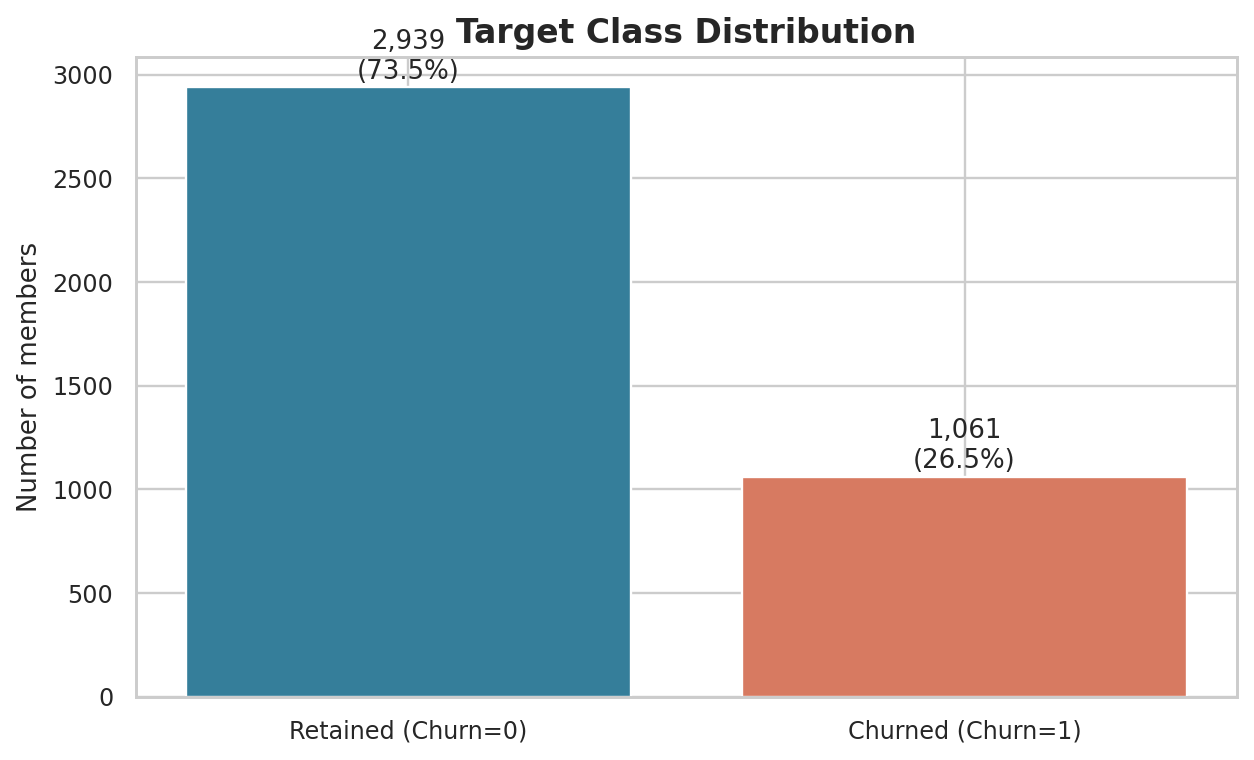

نسبة الانسحاب في هذه المجموعة: 26.52%
هذه النسبة تصف المجموعة المتاحة فقط ولا تمثل بالضرورة ناديًا حقيقيًا أو سوقًا آخر.


In [5]:
display(Image(filename=str(FIGURES_DIR / "target_distribution.png")))
print("نسبة الانسحاب في هذه المجموعة:", f"{df['Churn'].mean():.2%}")
print("هذه النسبة تصف المجموعة المتاحة فقط ولا تمثل بالضرورة ناديًا حقيقيًا أو سوقًا آخر.")

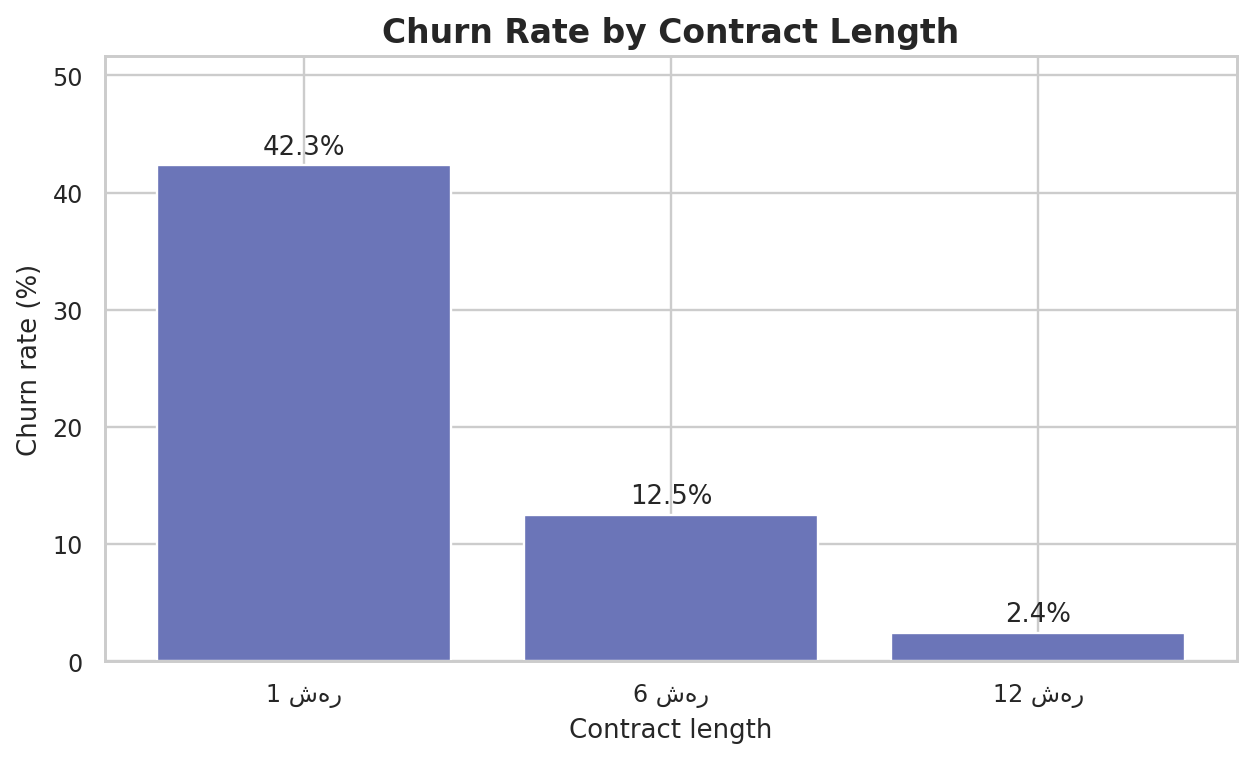

,Contract_period,عدد_المشتركين,نسبة_الانسحاب
0,1,2207,42.3%
1,6,833,12.5%
2,12,960,2.4%


In [6]:
display(Image(filename=str(FIGURES_DIR / "churn_by_contract.png")))
contract_summary = df.groupby("Contract_period").agg(عدد_المشتركين=("Churn","size"), نسبة_الانسحاب=("Churn","mean")).reset_index()
contract_summary["نسبة_الانسحاب"] = contract_summary["نسبة_الانسحاب"].map(lambda x: f"{x:.1%}")
display(contract_summary)

### ماذا تعني مقارنة مدة العقد؟

يساعد هذا الرسم على فحص الاختلاف في معدلات الانسحاب بين مدد العقود. لكنه لا يثبت أن تغيير مدة العقد وحده سيمنع الانسحاب؛ قد ترتبط مدة العقد بعوامل أخرى مثل الالتزام أو نوع العرض أو سلوك الحضور.

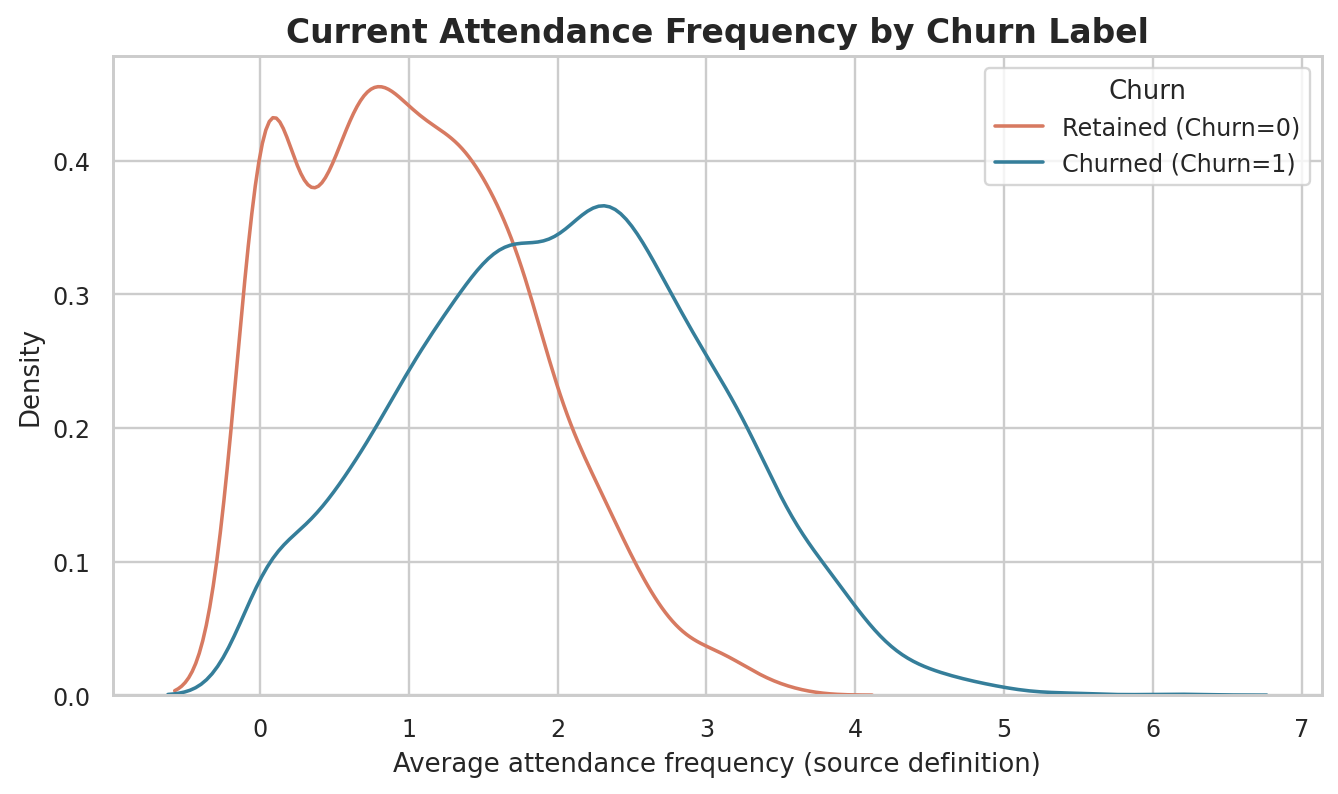

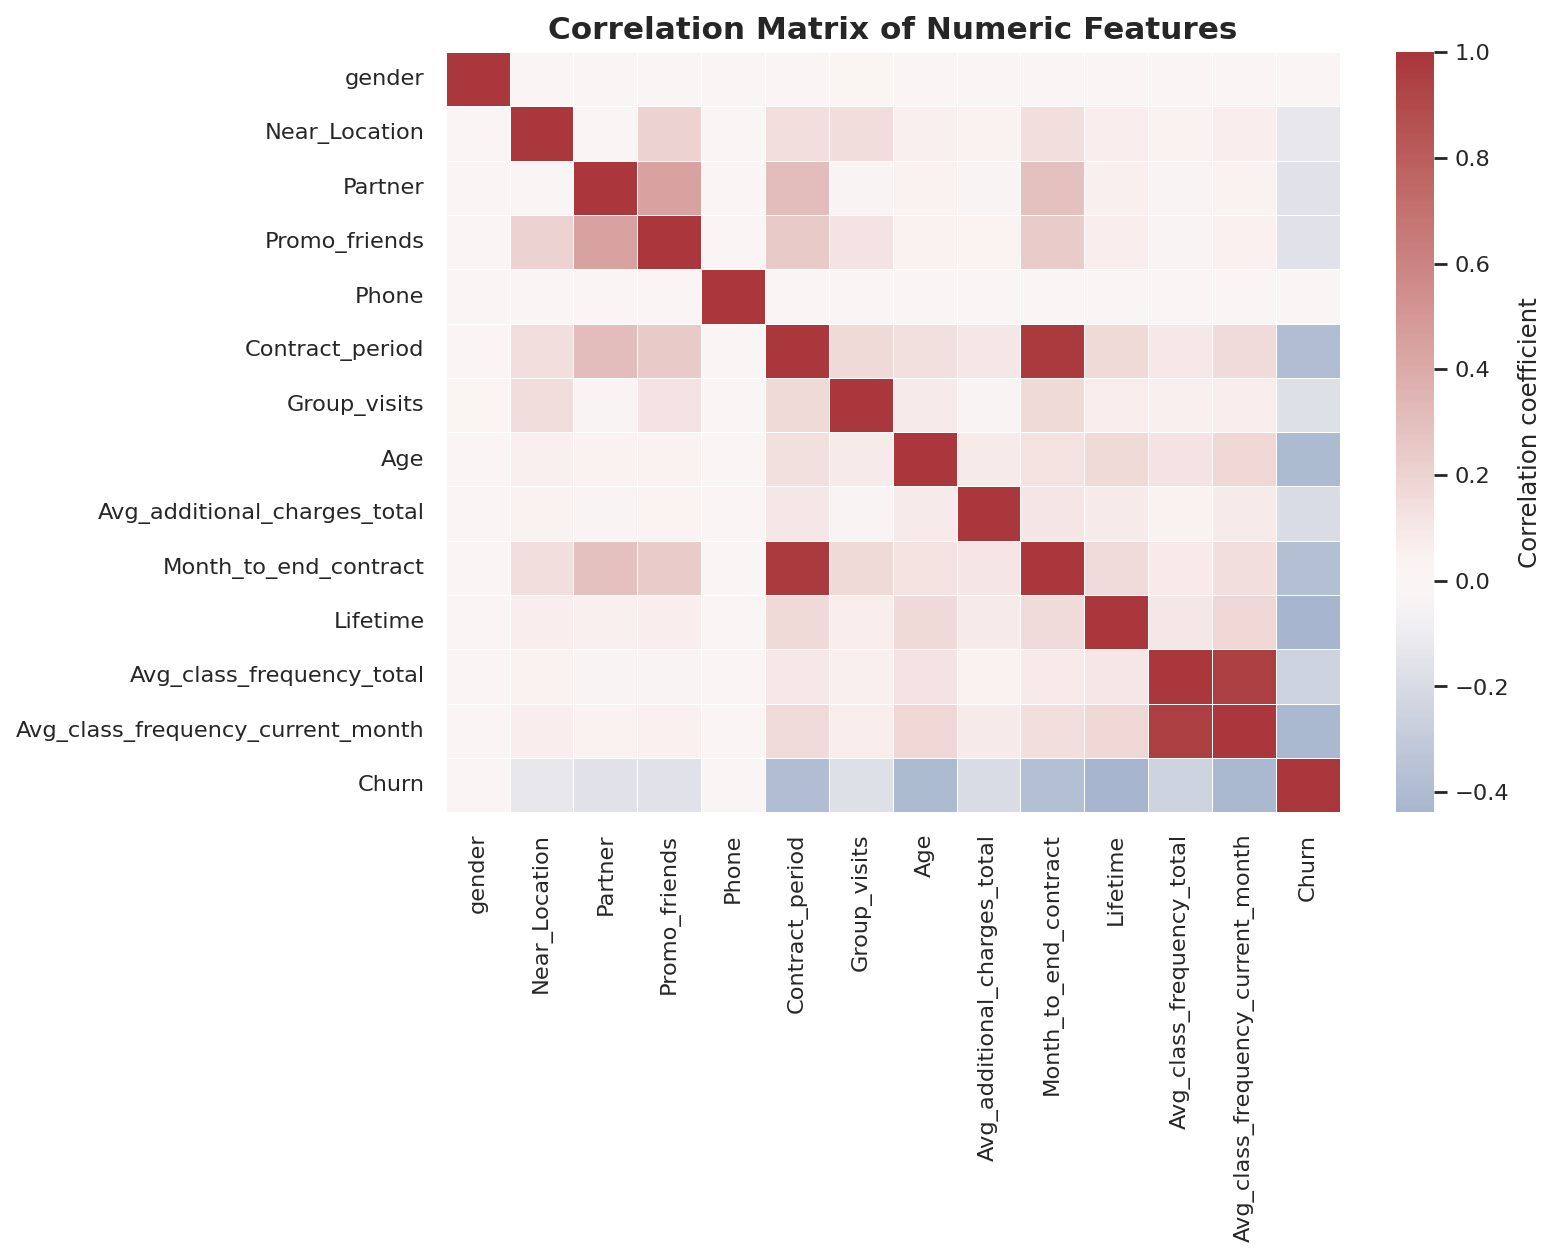

In [7]:
display(Image(filename=str(FIGURES_DIR / "frequency_by_churn.png")))
display(Image(filename=str(FIGURES_DIR / "correlation_matrix.png")))

### ملاحظات عن الرسوم

- قارن توزيع تكرار الحضور بين الفئتين؛ يظهر في هذه البيانات أن سجل الحضور يرتبط بقوة بملصق الانسحاب.
- الارتباط العددي وسيلة لوصف علاقة خطية، ولا يثبت السببية. كما أن الارتباط لا يلتقط كل العلاقات غير الخطية.
- ينبغي أن تكون متغيرات الحضور المستخدمة في أي تطبيق فعلي متاحة قبل القرار المراد التنبؤ به، لا بعده.

<a id="هندسة-الخصائص"></a>
## 5. هندسة الخصائص

هندسة الخصائص هي اشتقاق معلومات جديدة من الأعمدة المتاحة، عندما يكون لذلك معنى مرتبط بالمشكلة. أضفنا سبع خصائص مشتقة، ثم اختبرنا هل تحسّن أداء النموذج بدل افتراض ذلك مسبقًا.

In [8]:
from src.features import GymFeatureEngineer

X = df.drop(columns=["Churn"]).copy()
y = df["Churn"].astype(int).copy()
X_engineered = GymFeatureEngineer().fit_transform(X)
new_features = [c for c in X_engineered.columns if c not in X.columns]
print(f"عدد الخصائص الأصلية: {X.shape[1]}")
print(f"عدد الخصائص بعد الهندسة: {X_engineered.shape[1]}")
display(pd.DataFrame({"الخاصية المشتقة": new_features, "ما الذي تمثله": [
    "الفرق بين التكرار الحالي والمتوسط التاريخي",
    "التكرار الحالي نسبة إلى التكرار التاريخي؛ تتم معالجة اللانهاية/القيم غير المعرفة داخل خط المعالجة",
    "مدة العلاقة مقسومة على مدة العقد",
    "الأشهر المتبقية نسبة إلى مدة العقد",
    "الإنفاق الإضافي موزعًا على مدة العلاقة + 1 لتجنب القسمة على صفر",
    "مؤشر لعقد مدته شهر واحد",
    "مؤشر لعقد مدته 6 أشهر أو أكثر"
]}))
display(X_engineered[new_features].head())

عدد الخصائص الأصلية: 13
عدد الخصائص بعد الهندسة: 20


,الخاصية المشتقة,ما الذي تمثله
0,Frequency_change_current_vs_total,الفرق بين التكرار الحالي والمتوسط التاريخي
1,Frequency_ratio_current_vs_total,التكرار الحالي نسبة إلى التكرار التاريخي؛ تتم ...
2,Lifetime_to_contract_ratio,مدة العلاقة مقسومة على مدة العقد
3,Remaining_contract_ratio,الأشهر المتبقية نسبة إلى مدة العقد
4,Additional_charges_per_lifetime_month,الإنفاق الإضافي موزعًا على مدة العلاقة + 1 لتج...
5,Is_monthly_contract,مؤشر لعقد مدته شهر واحد
6,Is_long_contract,مؤشر لعقد مدته 6 أشهر أو أكثر


,Frequency_change_current_vs_total,Frequency_ratio_current_vs_total,Lifetime_to_contract_ratio,Remaining_contract_ratio,Additional_charges_per_lifetime_month,Is_monthly_contract,Is_long_contract
0,-0.020398,0.000000,0.500000,0.833333,3.556868,0,1
1,-0.012693,0.993399,0.583333,1.000000,14.150367,0,1
2,-0.122596,0.934056,2.000000,1.000000,43.149493,1,0
3,0.151582,1.047286,0.166667,1.000000,20.889954,0,1
4,0.006194,1.005560,3.000000,1.000000,49.590566,1,0


### منع تسرب البيانات

جميع الخصائص المشتقة أعلاه تعتمد على أعمدة الإدخال فقط ولا تستخدم `Churn`. تتم عمليات التعويض والتحجيم عند الحاجة داخل `Pipeline` حتى تُتعلّم من بيانات التدريب فقط.

هناك فرق بين تسرب الهدف الواضح (إدخال عمود يكشف النتيجة نفسها)، وبين استخدام خاصية مرتبطة جدًا بالانسحاب. العلاقة القوية لا تعني تلقائيًا وجود تسرب، لكن يجب التأكد من توقيت الخصائص بالنسبة إلى لحظة التنبؤ.

<a id="منهجية-التجارب"></a>
## 6. منهجية التجارب ومقارنة النماذج

استخدمنا تقسيمًا طبقيًا بنسبة 80% للتدريب و20% للاختبار، مع `random_state=42`. تمت مقارنة الخوارزميات عبر 3 طيات طبقية داخل مجموعة التدريب. مجموعة الاختبار النهائية لم تُستخدم لاختيار النموذج أو المعاملات أو عتبة القرار.

جرّبنا نماذج مختلفة في التعقيد: نموذجًا مرجعيًا بسيطًا، والانحدار اللوجستي، وشجرة القرار، والغابات العشوائية وExtra Trees، وGradient Boosting، وHistGradientBoosting، وKNN، وSVC. كما قورنت الخصائص الأصلية بالخصائص المهندسة.

المقياس الأساسي لترتيب التجارب هو `PR-AUC` (متوسط الدقة Average Precision)، وهو مفيد عند تفاوت أعداد الفئات، مع مراجعة `ROC-AUC` وPrecision وRecall وF1 ومقاييس أخرى.

In [9]:
from src.train import run_experiments

# النتائج المحفوظة في الحزمة جاهزة للعرض. اجعل القيمة True لإعادة تدريب كل التجارب من الصفر.
RETRAIN_FROM_SCRATCH = False
results = run_experiments(DATA_PATH, PROJECT_ROOT, force=RETRAIN_FROM_SCRATCH)
print("النموذج المختار:", results["best_model"])
print("مجموعة الخصائص:", results["best_feature_set"])
print("متوسط PR-AUC في CV:", f"{results['cv_best_mean_pr_auc']:.2%}")
print("متوسط ROC-AUC في CV:", f"{results['cv_best_mean_roc_auc']:.2%}")
print("المعاملات المختارة:", results["best_hyperparameters"])

النموذج المختار: HistGradientBoosting
مجموعة الخصائص: engineered
متوسط PR-AUC في CV: 97.32%
متوسط ROC-AUC في CV: 98.79%
المعاملات المختارة: {'model__learning_rate': 0.08, 'model__max_iter': 160, 'model__max_leaf_nodes': 7}


In [10]:
cv_results = pd.read_csv(REPORTS_DIR / "model_comparison_cv.csv")
cols = ["model", "feature_set", "accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
cv_view = cv_results[cols].copy().sort_values("pr_auc", ascending=False)
cv_view = cv_view.rename(columns={"model":"النموذج", "feature_set":"الخصائص", "accuracy":"Accuracy", "balanced_accuracy":"Balanced Accuracy", "precision":"Precision", "recall":"Recall", "f1":"F1", "roc_auc":"ROC-AUC", "pr_auc":"PR-AUC"})
display(cv_view.style.format({c:"{:.3f}" for c in cv_view.columns if c not in ["النموذج","الخصائص"]}))

,النموذج,الخصائص,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,HistGradientBoosting,engineered,0.953,0.933,0.932,0.889,0.910,0.988,0.973
1,GradientBoosting,engineered,0.952,0.921,0.961,0.854,0.904,0.986,0.970
2,RandomForest,engineered,0.950,0.924,0.941,0.868,0.903,0.984,0.969
3,ExtraTrees,engineered,0.944,0.912,0.940,0.843,0.889,0.984,0.965
4,SVC,engineered,0.943,0.911,0.938,0.842,0.887,0.982,0.963
5,HistGradientBoosting,original,0.928,0.899,0.887,0.836,0.861,0.978,0.951
6,LogisticRegression,engineered,0.928,0.898,0.887,0.834,0.860,0.975,0.946
7,LogisticRegression,original,0.929,0.901,0.887,0.841,0.863,0.976,0.945
8,SVC,original,0.920,0.889,0.868,0.824,0.846,0.968,0.930
9,KNN,engineered,0.926,0.876,0.939,0.769,0.845,0.964,0.927


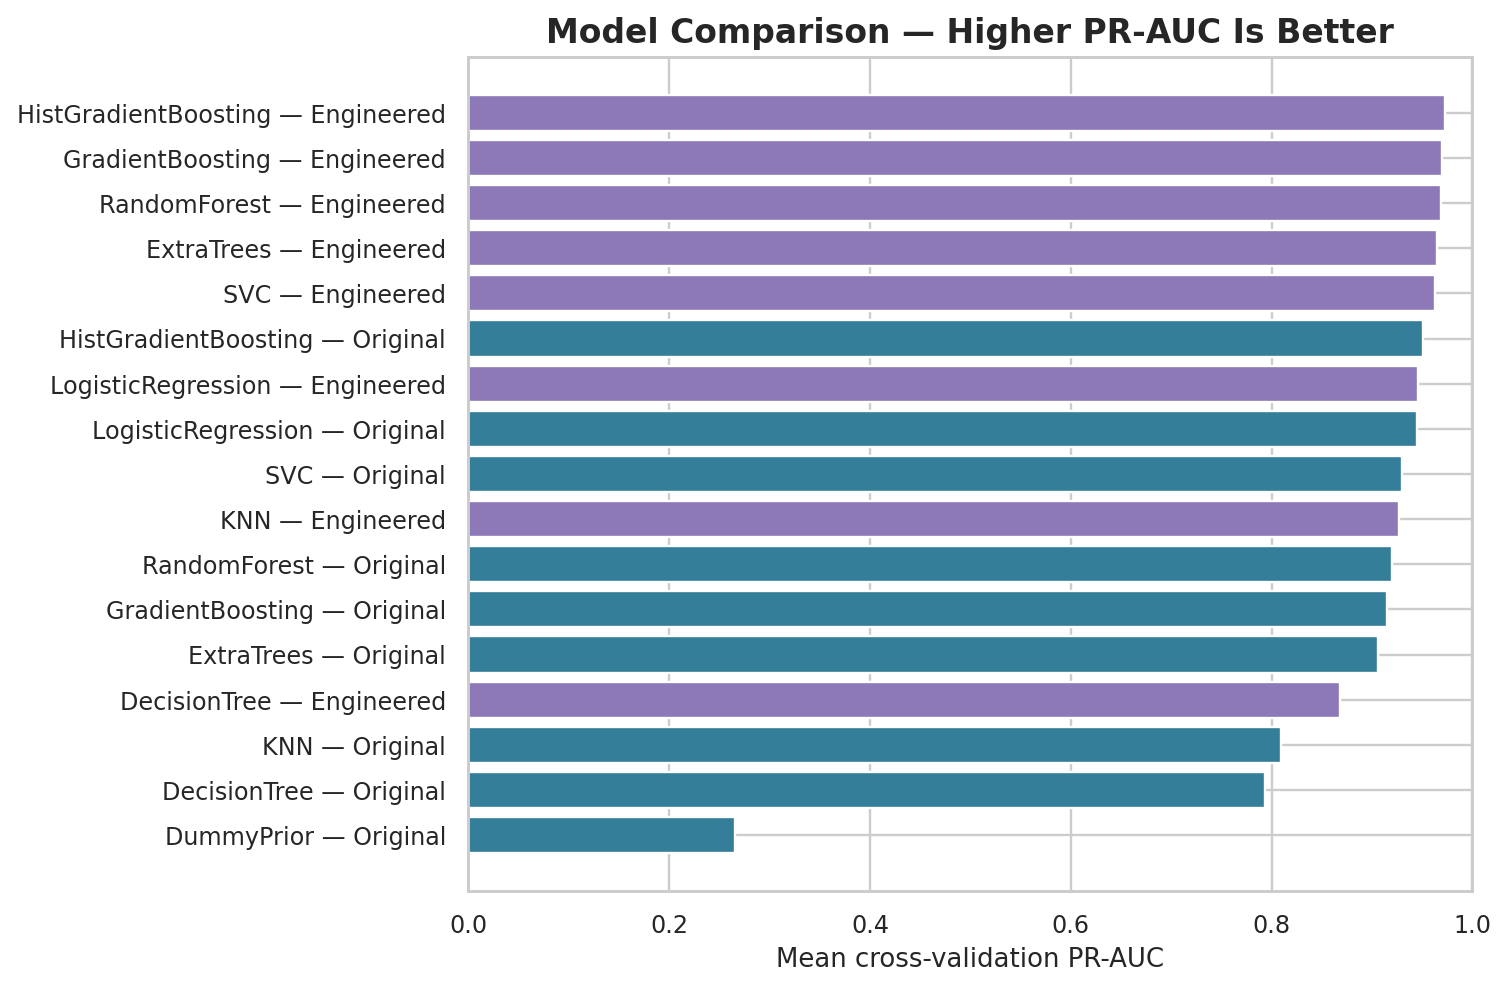

In [11]:
display(Image(filename=str(FIGURES_DIR / "model_comparison_pr_auc.png")))

<a id="اختيار-النموذج"></a>
## 7. أثر الخصائص واختيار النموذج

لم نختَر النموذج لأنه الأكثر تعقيدًا أو لأن نتيجته النهائية بدت أجمل، بل اعتمدنا متوسط `PR-AUC` في التحقق المتقاطع داخل التدريب. في هذه التجربة، حقق `HistGradientBoosting` مع الخصائص المهندسة أعلى متوسط PR-AUC.

HistGradientBoosting مع الخصائص الأصلية: 95.12% PR-AUC
HistGradientBoosting مع الخصائص المهندسة: 97.32% PR-AUC
التغير: +2.20 نقطة مئوية


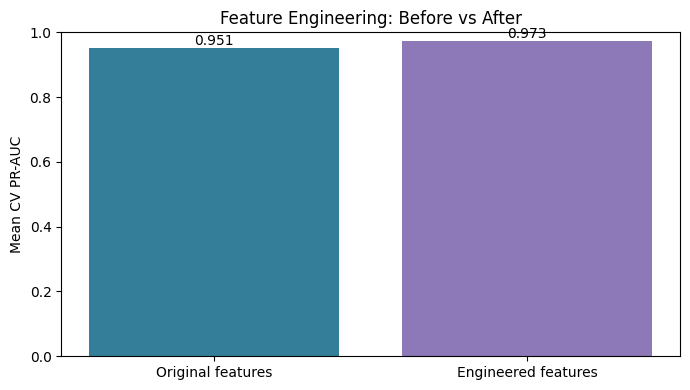

In [12]:
# مقارنة قبل/بعد هندسة الخصائص للنموذج الفائز في كلتا الحالتين
comparison = cv_results[(cv_results["model"] == "HistGradientBoosting")].set_index("feature_set")
raw_pr = float(comparison.loc["original", "pr_auc"])
engineered_pr = float(comparison.loc["engineered", "pr_auc"])
print(f"HistGradientBoosting مع الخصائص الأصلية: {raw_pr:.2%} PR-AUC")
print(f"HistGradientBoosting مع الخصائص المهندسة: {engineered_pr:.2%} PR-AUC")
print(f"التغير: {(engineered_pr-raw_pr)*100:+.2f} نقطة مئوية")
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(["Original features", "Engineered features"], [raw_pr, engineered_pr], color=["#357E9A", "#8D79B8"])
ax.set_ylim(0,1); ax.set_ylabel("Mean CV PR-AUC"); ax.set_title("Feature Engineering: Before vs After")
for i,v in enumerate([raw_pr, engineered_pr]): ax.text(i, v+0.01, f"{v:.3f}", ha="center")
fig.tight_layout(); plt.show(); plt.close(fig)

### لماذا نستخدم `PR-AUC`؟

- `Precision`: من الحالات التي صُنفت على أنها معرضة للانسحاب، كم حالة كانت فعلًا من الفئة 1؟
- `Recall`: من كل حالات الانسحاب في الحقيقة، كم حالة اكتشفها النموذج؟
- `F1`: يوازن بين Precision وRecall.
- `F2`: يعطي Recall وزنًا أعلى من Precision، وهو مناسب عندما نريد تقليل الحالات التي يفشل النموذج في تنبيهنا إليها، مع قبول احتمال زيادة الإنذارات الكاذبة.
- `ROC-AUC` و`PR-AUC`: يقيسان جودة ترتيب الدرجات عبر عتبات مختلفة، ولا يعني أي منهما أن الدرجة الاحتمالية مُعايرة.

## اختيار عتبة القرار

النموذج يعطي درجة/احتمالًا بين 0 و1؛ اختيار عتبة يحول الدرجة إلى فئة. العتبة ليست حقيقة علمية ثابتة، بل تعتمد على الهدف وكلفة نوعي الخطأ. هنا اخترنا العتبة من تنبؤات خارج الطية داخل التدريب فقط، مع تعظيم F2. لم نستخدم الاختبار النهائي لهذا القرار.

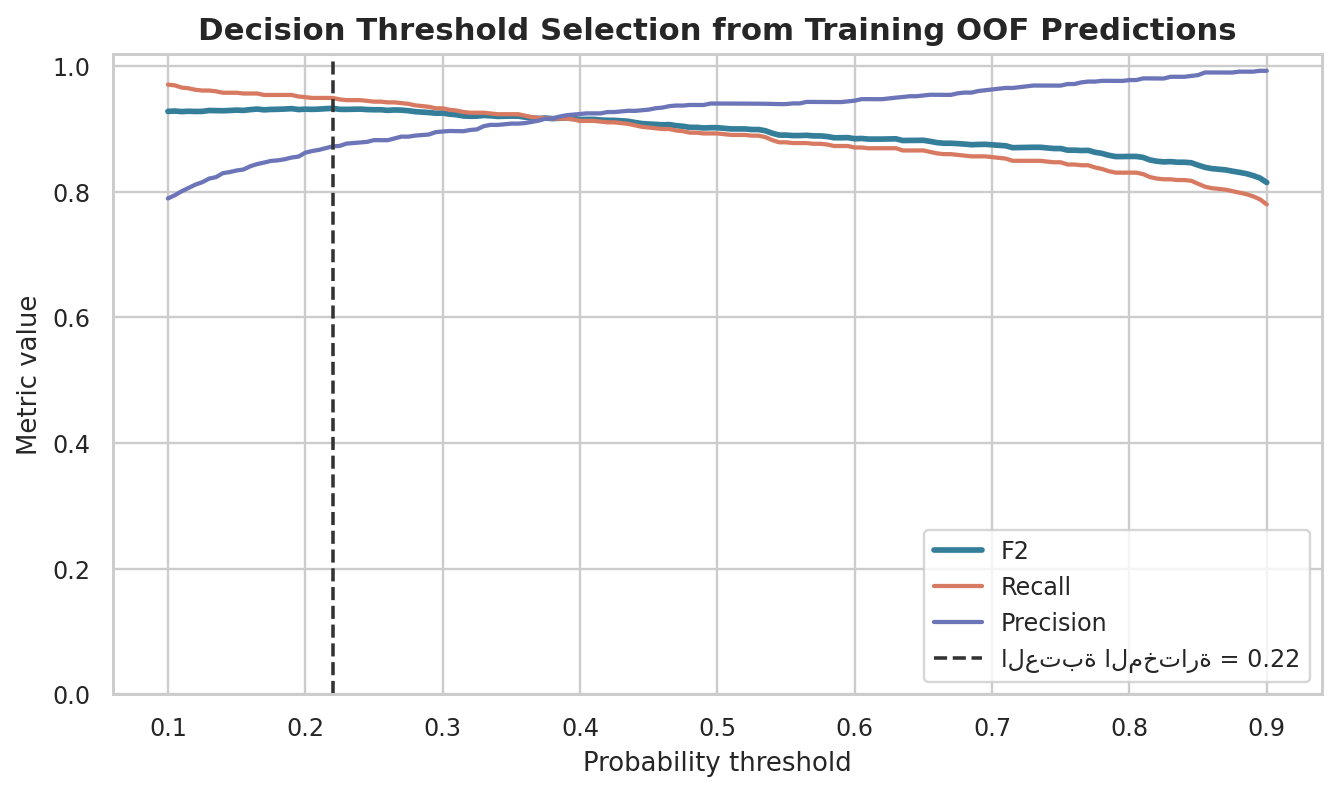

العتبة المختارة: 0.22
طريقة الاختيار: maximize F2 using nested OOF probabilities from training split only; each outer validation fold is excluded from hyperparameter selection


In [13]:
display(Image(filename=str(FIGURES_DIR / "threshold_selection.png")))
print("العتبة المختارة:", results["threshold_selection"]["selected_threshold"])
print("طريقة الاختيار:", results["threshold_selection"]["method"])

<a id="التقييم-النهائي"></a>
## 8. التقييم النهائي وتحليل الأخطاء

بعد اختيار النموذج والخصائص والعتبة باستخدام بيانات التدريب فقط، قُيّم النموذج على الاختبار النهائي. نعرض النتيجة عند العتبة المختارة، وكذلك عند 0.50 كتحليل حساسية فقط؛ لم تُستخدم نتيجة الاختبار لتعديل العتبة.

In [14]:
selected = results["final_test_metrics_selected_threshold"]
default = results["final_test_metrics_default_threshold_0_5"]
metric_labels = {
    "accuracy":"Accuracy", "balanced_accuracy":"Balanced Accuracy", "precision":"Precision",
    "recall":"Recall", "f1":"F1", "f2":"F2", "roc_auc":"ROC-AUC",
    "pr_auc_average_precision":"PR-AUC (Average Precision)"
}
metrics_table = pd.DataFrame([
    {"المقياس": label, "العتبة المختارة": selected[key], "العتبة 0.50": default[key]}
    for key,label in metric_labels.items()
])
metrics_table["العتبة المختارة"] = metrics_table["العتبة المختارة"].map(lambda x:f"{x:.2%}")
metrics_table["العتبة 0.50"] = metrics_table["العتبة 0.50"].map(lambda x:f"{x:.2%}")
display(metrics_table)
print("النموذج:", results["best_model"])
print("الخصائص:", results["best_feature_set"])
print("العتبة الأساسية:", selected["threshold"])
print(f"مصفوفة الالتباس: TN={selected['tn']}, FP={selected['fp']}, FN={selected['fn']}, TP={selected['tp']}")

,المقياس,العتبة المختارة,العتبة 0.50
0,Accuracy,95.38%,96.38%
1,Balanced Accuracy,94.89%,94.37%
2,Precision,89.24%,95.98%
3,Recall,93.87%,90.09%
4,F1,91.49%,92.94%
5,F2,92.90%,91.21%
6,ROC-AUC,99.04%,99.04%
7,PR-AUC (Average Precision),97.96%,97.96%


النموذج: HistGradientBoosting
الخصائص: engineered
العتبة الأساسية: 0.22
مصفوفة الالتباس: TN=564, FP=24, FN=13, TP=199


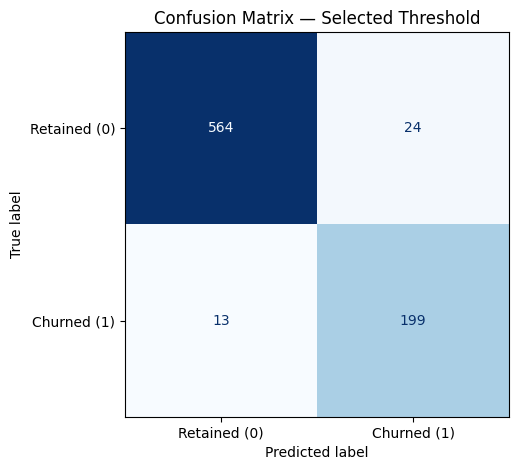

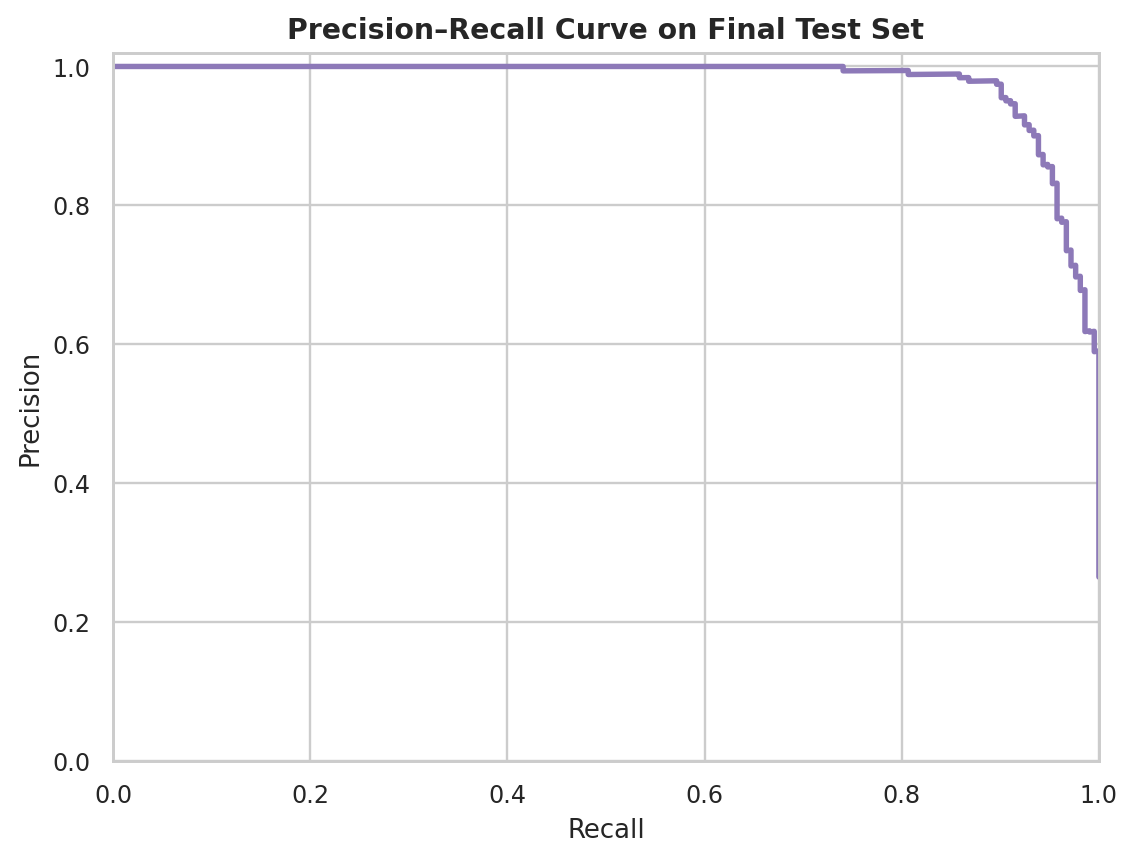

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

test_data = pd.read_csv(REPORTS_DIR / "final_test_predictions.csv")
cm = confusion_matrix(test_data["actual_Churn"], test_data["predicted_Churn"], labels=[0,1])
fig, ax = plt.subplots(figsize=(5.8,4.8))
display_obj = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Retained (0)", "Churned (1)"])
display_obj.plot(ax=ax, values_format="d", colorbar=False, cmap="Blues")
ax.set_title("Confusion Matrix — Selected Threshold")
fig.tight_layout(); plt.show(); plt.close(fig)

display(Image(filename=str(FIGURES_DIR / "test_precision_recall_curve.png")))

### كيف نقرأ مصفوفة الالتباس؟

عند العتبة المختارة كانت النتيجة: **566** حالة عدم انسحاب صحيحة، و**199** حالة انسحاب صحيحة، و**22** إنذارًا كاذبًا، و**13** حالة انسحاب لم يكتشفها النموذج. لا يوجد نموذج خالٍ من الخطأ؛ وإدارة النادي هي التي تحدد مدى قبول المتابعة الإضافية مقابل تفويت حالة معرضة للانسحاب.

<a id="حدود-المشروع"></a>
## 9. تفسير النموذج وحدود المشروع

نستخدم أهمية الخصائص بطريقة Permutation Importance. تعني هذه الطريقة أن خلط قيم خاصية في مجموعة التقييم يقلل أداء النموذج بمقدار معين إذا كانت الخاصية مفيدة لهذا النموذج. لكنها لا تثبت تأثيرًا سببيًا، وقد يتأثر التفسير بوجود خصائص مترابطة.

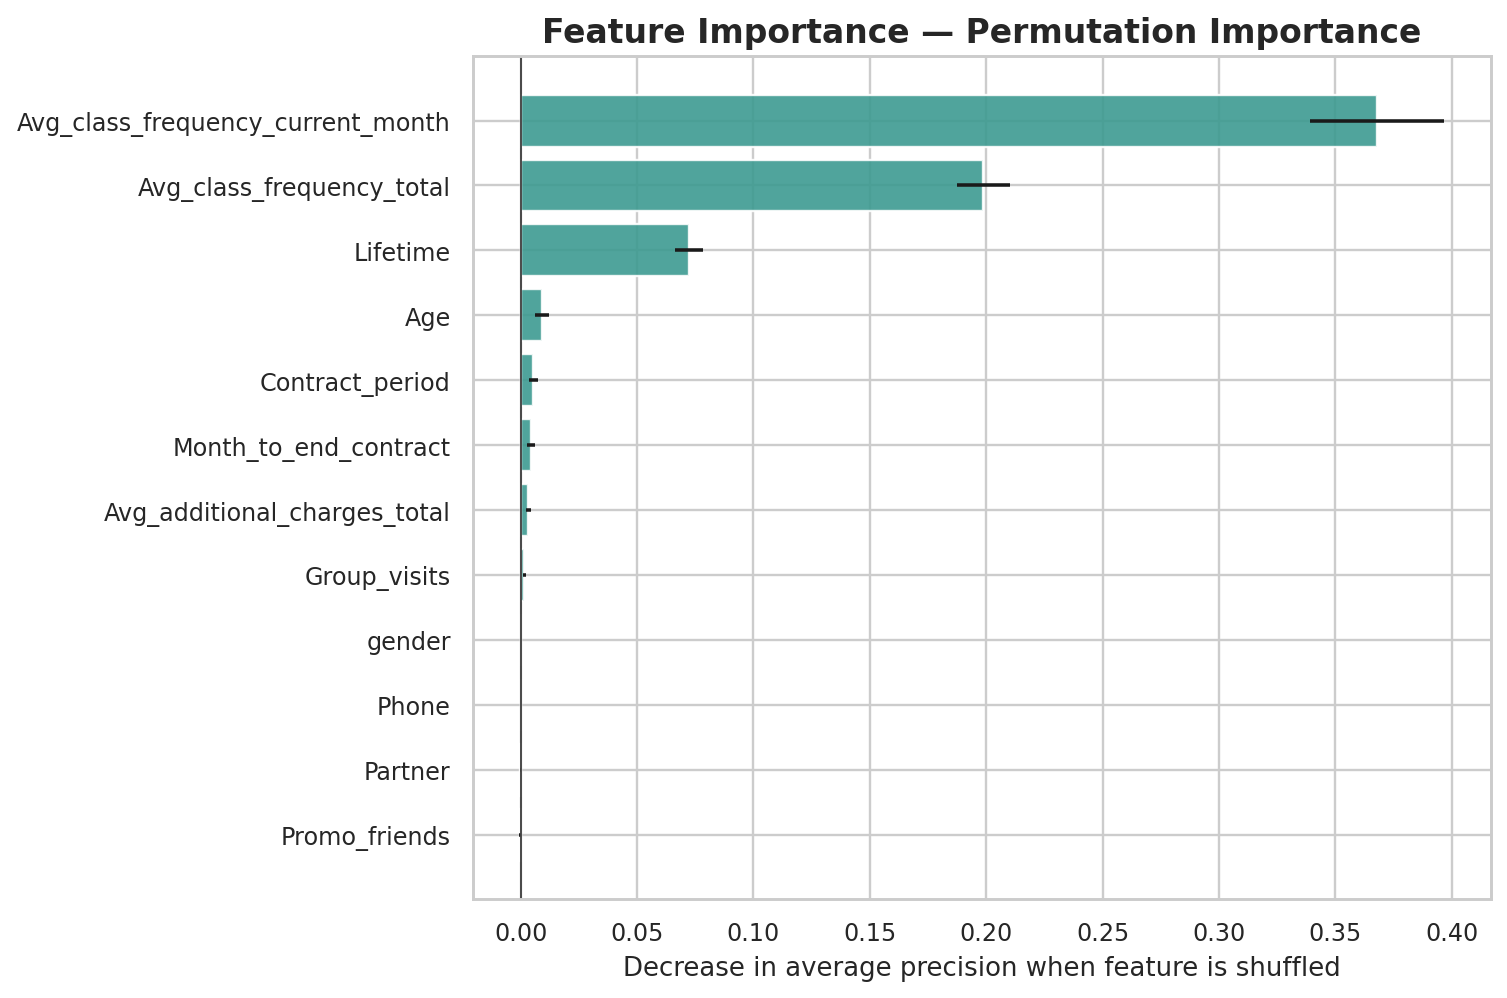

,feature,importance_mean,importance_std
0,Avg_class_frequency_current_month,0.367894,0.028904
1,Avg_class_frequency_total,0.198809,0.011515
2,Lifetime,0.072224,0.005996
3,Age,0.009163,0.003137
4,Contract_period,0.005515,0.001809
5,Month_to_end_contract,0.004439,0.001560
6,Avg_additional_charges_total,0.003345,0.001161
7,Group_visits,0.001674,0.000805
8,gender,0.000085,0.000079
9,Phone,0.000000,0.000000


In [16]:
display(Image(filename=str(FIGURES_DIR / "feature_importance.png")))
importance = pd.read_csv(REPORTS_DIR / "feature_importance_permutation.csv")
display(importance.head(12))

### القيود العلمية التي يجب أن نكون قادرين على شرحها

1. الملف يحتوي على لقطة سجلات من مجموعة واحدة ولا يتضمن تاريخًا مستقلًا لكل سجل؛ لذا فالتقسيم العشوائي الطبقي لا يعادل اختبارًا زمنيًا على أشهر مستقبلية.
2. قد ترتبط الخصائص ارتباطًا قويًا بملصق الانسحاب؛ يجب التحقق من أن كل خاصية كانت متاحة فعلًا في الزمن السابق للانسحاب. توثيق المجموعة المتداول يصف بيانات الشهر السابق، ولكن يلزم التحقق من المصدر الأصلي ومن نظام النادي قبل التطبيق.
3. نتائج الاختبار ليست ضمانًا للأداء على نادٍ يمني أو على أعضاء جدد. نحتاج إلى بيانات محلية حديثة مجهولة الهوية وتقييم خارجي.
4. درجات النموذج ليست يقينًا. فحص المعايرة والعدالة حسب المجموعات يحتاج عملًا إضافيًا.
5. لا يجوز أن يستعمل النموذج وحده لحرمان المشترك من خدمة أو تعديل سعره؛ الغرض هو مساعدة الإدارة على عرض متابعة إنسانية أفضل.

**الخطوة المستقبلية الأهم:** في نظام التخرج، سجّل لقطات شهرية لكل عضو. استخدم خصائص الشهر T للتنبؤ بالانسحاب خلال T+1 (أو عدم التجديد ضمن أفق محدد)، ثم اختبر على أشهر لم تظهر في التدريب.

<a id="تجربة-تنبؤ"></a>
## 10. تجربة تنبؤ توضيحية

سنستخدم صفًا من الاختبار النهائي، ونزيل منه عمود الهدف قبل إدخاله إلى النموذج. بهذه الطريقة لا نمرر النتيجة الصحيحة إلى النموذج أثناء التنبؤ. ثم نقارن النتيجة الفعلية لأغراض الشرح بعد حساب التوقع.

In [17]:
import joblib
bundle = joblib.load(MODEL_PATH)
feature_columns = bundle["feature_columns"]
example = test_data[feature_columns].iloc[[0]].copy()
probability = float(bundle["pipeline"].predict_proba(example)[0,1])
threshold = float(bundle["decision_threshold"])
prediction = int(probability >= threshold)
actual = int(test_data.iloc[0]["actual_Churn"])
print("خصائص الصف المستخدم (دون الهدف):")
display(example.T.rename(columns={example.index[0]:"القيمة"}))
print(f"درجة النموذج: {probability:.3f}")
print(f"عتبة القرار: {threshold:.2f}")
print("فئة النموذج:", prediction, "(1 = انسحاب وفق ترميز المصدر)" if prediction else "(0 = عدم انسحاب وفق ترميز المصدر)")
print("الفئة الفعلية (للمقارنة بعد التنبؤ فقط):", actual)

خصائص الصف المستخدم (دون الهدف):


,القيمة
gender,1.000000
Near_Location,0.000000
Partner,1.000000
Promo_friends,0.000000
Phone,1.000000
Contract_period,1.000000
Group_visits,1.000000
Age,29.000000
Avg_additional_charges_total,21.256169
Month_to_end_contract,1.000000


درجة النموذج: 0.003
عتبة القرار: 0.22
فئة النموذج: 0 (0 = عدم انسحاب وفق ترميز المصدر)
الفئة الفعلية (للمقارنة بعد التنبؤ فقط): 0


## 11. قاموس مختصر للمصطلحات

| المصطلح | المعنى المبسط |
|---|---|
| Target / الهدف | النتيجة التي نحاول التنبؤ بها، هنا `Churn`. |
| Feature / خاصية | معلومة تُستخدم كمدخل للنموذج مثل مدة العقد أو تكرار الحضور. |
| EDA | تحليل استكشافي لفهم شكل البيانات والعلاقات فيها. |
| Feature Engineering | اشتقاق خصائص مفيدة من الأعمدة الموجودة. |
| Pipeline | سلسلة معالجة وتدريب تُنفّذ بنفس الطريقة على التدريب والتنبؤ. |
| Cross-validation | تقسيم بيانات التدريب إلى طيات لقياس ثبات النموذج. |
| Holdout Test | بيانات احتفظنا بها للتقييم النهائي بعد تثبيت الاختيارات. |
| Precision | مدى صحة الإنذارات التي أصدرها النموذج. |
| Recall | نسبة الحالات الإيجابية الحقيقية التي اكتشفها النموذج. |
| PR-AUC | جودة الترتيب بين Precision وRecall عبر العتبات، مفيد مع تفاوت الفئات. |
| Threshold | الحد الذي يحوّل الدرجة الاحتمالية إلى فئة 0 أو 1. |
| Data Leakage | استخدام معلومة لا ينبغي أن تكون متاحة للتدريب أو وقت التنبؤ. |
| Permutation Importance | تقدير فائدة الخاصية عبر قياس أثر خلط قيمها على أداء النموذج. |

## 12. الخلاصة والمراجع

أثبتت التجربة أن النماذج المختلفة لا تحقق الأداء نفسه، وأن الخصائص المهندسة حسّنت متوسط PR-AUC في هذه المجموعة. تم اختيار HistGradientBoosting بناءً على التحقق المتقاطع، واختيار عتبة القرار من بيانات التدريب فقط، ثم تقييم الإعداد النهائي على اختبار منفصل.

لكن النتيجة النهائية تعني النجاح داخل هذه البيانات فقط. لإثبات قابلية الاستخدام في الواقع نحتاج إلى بيانات نادٍ حقيقي بعد إزالة المعلومات الشخصية، ولقطات زمنية، واختبار زمني وخارجي.

**المصدر الأساسي للبيانات:** [Kaggle — Gym Customers Features and Churn](https://www.kaggle.com/datasets/adrianvinueza/gym-customers-features-and-churn)

**مرجع ثانوي لوصف الأعمدة ومنهجية شائعة للمجموعة:** [Model Fitness Machine Learning — GitHub](https://github.com/sgcuervo/model-fitness-machine-learning)

راجع كذلك `README.md` و`reports/FINAL_RESULTS_AR.md` للحصول على تعليمات التشغيل والنتائج التفصيلية.